<div style="padding: 1em 0.5em; color: #fff; background-color: #0969da; font-size: 1.2em;">
    Lab 3 (ter) — Ablation : température et alpha
</div>
<div style="border-left: 2px solid #0969da; min-height: 1.5em;margin-left: 1em;padding: 1em;">
    - Mesurer ce que la distillation apporte vraiment, face à un témoin sans teacher<br>
    - Balayer une grille température × alpha sur le student k-mer<br>
    - Lire le compromis : quand les cibles douces aident-elles, et quand cessent-elles d'aider ?<br>
</div>

<div style="border-left: 4px solid #0969da; background-color: #f2f6fd; padding: 0.9em 1.1em; color: #24292f;">
  <strong style="color: #0969da;">Version corrigée &mdash; solution de référence</strong><br>
  Ce notebook contient <strong>toutes les réponses</strong>. Il n'est pas à compléter et n'est pas à rendre.<br>
  Il prolonge <code>03_knowledge_distillation.ipynb</code> : exécutez-le après lui.
</div>

<div style="height: 3px; margin: 2em 0 1.5em 0; background: linear-gradient(90deg, #0969da 0%, #0969da 55%, rgba(9,105,218,0.15) 100%);"></div>

Deux hyperparamètres pilotent la distillation :

- **`alpha`** dose le mélange entre étiquettes dures et cibles douces.
  `alpha=1.0` = aucune distillation (**le témoin**), `alpha=0.0` = imitation pure du teacher.
- **`temperature`** aplatit les probabilités du teacher. À `T=1` ses cibles ressemblent
  déjà à des 0/1 ; plus `T` monte, plus les écarts de confiance deviennent visibles.

L'écart entre la colonne `alpha=1.0` et les autres **est** le gain de la distillation.
Tout le reste n'est que réglage.

In [1]:
import sys
sys.path.append("src")

from pathlib import Path
import numpy as np
import pandas as pd
import torch

from data import load_all
from embeddings import load_supervised_embeddings
from featurize import kmer_matrix
from models.classifier_heads import MLPHead
from models.distillation import train_student
from eval import evaluate_logits, count_params, measure_latency_torch

EMB_DIR = "../../2-data/embeddings"
PROCESSED_DIR = "../../2-data/processed"
TEACHER_PATH = Path("../../2-data/models/teacher_mlp.pt")

In [2]:
X_train_emb, y_train, ids_train = load_supervised_embeddings(EMB_DIR, "train")
X_val_emb, y_val, ids_val = load_supervised_embeddings(EMB_DIR, "val")

# le teacher entraîné au notebook 02 (gelé : il ne sert qu'à produire des cibles douces)
ckpt = torch.load(TEACHER_PATH)
teacher = MLPHead(d_in=ckpt["d_in"]); teacher.load_state_dict(ckpt["state_dict"]); teacher.eval()

# les séquences des MÊMES fenêtres, retrouvées par leur id
splits = load_all(PROCESSED_DIR, max_rows=None)
train_df, val_df = splits["train"].set_index("id"), splits["val"].set_index("id")
train_seqs = train_df.loc[ids_train, "sequence"].tolist()
val_seqs = val_df.loc[ids_val, "sequence"].tolist()

y_train_t = torch.tensor(y_train, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32)

with torch.no_grad():
    teacher_logits_train = teacher(torch.tensor(X_train_emb, dtype=torch.float32))
    teacher_val_logits = teacher(torch.tensor(X_val_emb, dtype=torch.float32)).numpy()

teacher_metrics = evaluate_logits(teacher_val_logits, y_val)
print("teacher :", teacher_metrics)
print(len(train_seqs), "fenêtres d'entraînement |", len(val_seqs), "de validation")

teacher : {'accuracy': 0.959, 'f1': 0.9595261599210266}
4000 fenêtres d'entraînement | 1000 de validation


In [3]:
X_train_kmer = torch.tensor(kmer_matrix(train_seqs, k=4), dtype=torch.float32)
X_val_kmer = torch.tensor(kmer_matrix(val_seqs, k=4), dtype=torch.float32)
print("caractéristiques k-mer :", tuple(X_train_kmer.shape))

caractéristiques k-mer : (4000, 256)


<div style="height: 3px; margin: 2em 0 1.5em 0; background: linear-gradient(90deg, #0969da 0%, #0969da 55%, rgba(9,105,218,0.15) 100%);"></div>

#### **La grille**

Chaque case est un entraînement complet, avec un student **neuf** (sinon on mesurerait « plus d'époques », pas l'effet des hyperparamètres).

In [4]:
TEMPERATURES = [1.0, 4.0, 10.0]
ALPHAS = [1.0, 0.5, 0.0]          # 1.0 = aucune distillation (témoin)
EPOCHS = 60

records = []
for T in TEMPERATURES:
    for a in ALPHAS:
        torch.manual_seed(0)                      # un student NEUF à chaque case
        student = MLPHead(d_in=X_train_kmer.shape[1], d_hidden=32)
        student, _ = train_student(student, teacher_logits_train, X_train_kmer, y_train_t,
                                    epochs=EPOCHS, temperature=T, alpha=a, log_every=0)
        student.eval()
        with torch.no_grad():
            m = evaluate_logits(student(X_val_kmer).numpy(), y_val)
        records.append({"temperature": T, "alpha": a, **m})
        print(f"T={T:>4} | alpha={a:>3} | accuracy={m['accuracy']:.4f} | f1={m['f1']:.4f}")

results = pd.DataFrame(records)

T= 1.0 | alpha=1.0 | accuracy=0.8390 | f1=0.8441
T= 1.0 | alpha=0.5 | accuracy=0.8380 | f1=0.8433
T= 1.0 | alpha=0.0 | accuracy=0.8380 | f1=0.8433
T= 4.0 | alpha=1.0 | accuracy=0.8390 | f1=0.8441
T= 4.0 | alpha=0.5 | accuracy=0.8240 | f1=0.8311
T= 4.0 | alpha=0.0 | accuracy=0.8240 | f1=0.8298
T=10.0 | alpha=1.0 | accuracy=0.8390 | f1=0.8441
T=10.0 | alpha=0.5 | accuracy=0.8080 | f1=0.8049
T=10.0 | alpha=0.0 | accuracy=0.8040 | f1=0.7988


#### **Lecture des résultats**

In [5]:
table = results.pivot(index="temperature", columns="alpha", values="accuracy")
print("Accuracy de validation\n")
display(table.round(4))

# le témoin : alpha=1.0 = entraînement supervisé classique, sans le teacher
temoin = results[results.alpha == 1.0].accuracy.mean()
meilleur = results.accuracy.max()
best = results.loc[results.accuracy.idxmax()]
print(f"\ntémoin (alpha=1, sans distillation) : {temoin:.4f}")
print(f"meilleure combinaison : T={best.temperature}, alpha={best.alpha} -> {meilleur:.4f}")
print(f"gain apporté par la distillation : {(meilleur - temoin) * 100:+.2f} points")

Accuracy de validation



alpha,0.0,0.5,1.0
temperature,,,
1.0,0.838,0.838,0.839
4.0,0.824,0.824,0.839
10.0,0.804,0.808,0.839



témoin (alpha=1, sans distillation) : 0.8390
meilleure combinaison : T=1.0, alpha=1.0 -> 0.8390
gain apporté par la distillation : +0.00 points


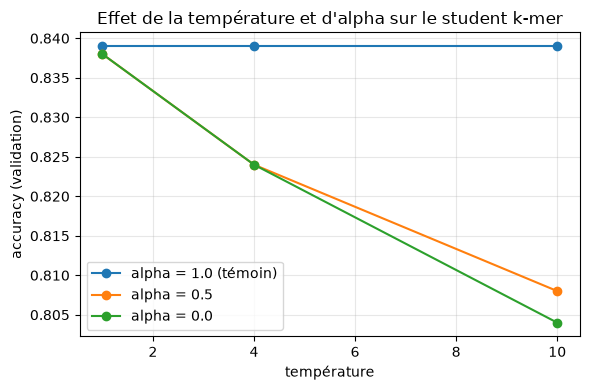

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
for a in ALPHAS:
    sub = results[results.alpha == a].sort_values("temperature")
    ax.plot(sub.temperature, sub.accuracy, marker="o",
            label=f"alpha = {a}" + (" (témoin)" if a == 1.0 else ""))
ax.set_xlabel("température"); ax.set_ylabel("accuracy (validation)")
ax.set_title("Effet de la température et d'alpha sur le student k-mer")
ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

#### **Point de contrôle**

Premier réflexe, une vérification de cohérence : la colonne `alpha=1.0` doit être
**identique pour les trois températures**. C'est le cas — normal, puisque à `alpha=1`
le terme de distillation est multiplié par zéro, et la température n'a plus aucun effet.
Si ces trois valeurs différaient, il y aurait un bug.

Et le résultat, sur ce jeu de données, est net : **la distillation n'apporte rien ici**.
Le témoin sans teacher fait aussi bien que la meilleure combinaison, et augmenter la
température *dégrade* le student (0,839 → 0,806 à T=10, alpha=0,5).

C'est un vrai résultat, pas un échec de manipulation, et il s'explique :

- Le student ne voit que des **fréquences de k-mers**. Il atteint déjà, avec les
  étiquettes dures, à peu près tout ce que cette représentation permet. Les cibles douces
  du teacher parlent d'une information (le contexte long vu par Evo2) que le student ne
  peut de toute façon pas exploiter — elles ajoutent du bruit plutôt que du signal.
- En binaire, la « dark knowledge » se réduit à un seul nombre, la confiance. C'est
  beaucoup plus pauvre que dans le cas multi-classes des résultats classiques sur
  ImageNet, où le teacher indique *quelles autres classes* il jugeait plausibles.
- Plus `T` monte, plus les cibles s'aplatissent vers 0,5 : on demande au student
  d'imiter une indécision, et on efface le signal des étiquettes.

À dire aux étudiants : **une ablation qui montre l'absence d'effet est un résultat
publiable**. La conclusion honnête est que le gain de l'atelier vient de la
représentation (Evo2 vs k-mers), pas du mécanisme de distillation en lui-même. Pour voir
la distillation aider, il faut un student capable d'absorber davantage — d'où
`03b_distillation_cnn_student.ipynb`.

<div style="margin-top: 3em;">
  <div style="height: 3px; background: linear-gradient(90deg, #0969da 0%, #0969da 55%, rgba(9,105,218,0.15) 100%);"></div>
  <div style="display: flex; align-items: center; gap: 0.9em; padding: 1.1em 1em; font-size: 0.9em; color: #57606a; background-color: #f2f6fd; border-radius: 0 0 6px 6px;">
    <svg width="34" height="34" viewBox="0 0 34 34" fill="none" style="flex: 0 0 auto;">
      <path d="M9 3c0 7 16 7 16 14S9 24 9 31" stroke="#0969da" stroke-width="2" stroke-linecap="round"/>
      <path d="M25 3c0 7-16 7-16 14s16 7 16 14" stroke="#0969da" stroke-width="2" stroke-linecap="round" opacity="0.45"/>
      <circle cx="17" cy="10" r="1.8" fill="#0969da"/>
      <circle cx="17" cy="24" r="1.8" fill="#0969da"/>
    </svg>
    <div style="flex: 1 1 auto;">
      <div style="color: #0969da; font-weight: 600; letter-spacing: 0.03em;">Lab 3 &mdash; ablation T / alpha</div>
      <div>Suite &rarr; <code>lab4/04_compression_analysis_and_wrapup.ipynb</code></div>
    </div>
    <div style="flex: 0 0 auto; text-align: right; border-right: 2px solid #0969da; padding-right: 0.9em;">
      <div style="font-weight: 600; color: #24292f;">AfricaBP &middot; bioAI Workshop</div>
      <div style="font-size: 0.85em;">AfricaBP 2026 &mdash; De l'ADN aux mod&egrave;les compress&eacute;s</div>
    </div>
  </div>
</div>